<a href="https://colab.research.google.com/github/VictorHugoTesti/FATEC-Processamento_Linguagem_Natural/blob/main/%5BPLN%5D_Aula10_Passo_a_Passo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Instalação e download de recursos

In [48]:
!pip install -q spacy scikit-learn transformers
!python -m spacy download pt_core_news_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [49]:
import random
import numpy as np
import spacy
import torch
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
from transformers import AutoTokenizer, AutoModel, pipeline

In [50]:
nlp = spacy.load("pt_core_news_sm")
print("Ambiente configurado com sucesso.")

Ambiente configurado com sucesso.


# Pipeline 1

In [51]:
aspectos = ["O atendimento", "O corretor", "A visita", "A negociação", "O apartamento",
            "O condomínio", "A entrega das chaves", "O contrato", "O financiamento", "A vistoria"]
avaliacoes_positivas = ["foi excelente", "foi rápido e eficiente", "superou minhas expectativas",
                        "foi ótimo, recomendo", "foi tranquilo do início ao fim",
                        "me deixou muito satisfeito", "foi muito bem feito",
                        "foi claro e organizado", "foi perfeito", "merece nota dez"]
avaliacoes_negativas = ["foi péssimo", "atrasou demais", "me deixou decepcionado",
                        "foi ruim, não recomendo", "foi confuso e demorado", "não foi resolvido",
                        "deu muito problema", "foi desorganizado", "foi uma decepção",
                        "não atendeu ao combinado"]

In [52]:
random.seed(42)
positivos = random.sample([f"{a} {p}." for a in aspectos for p in avaliacoes_positivas], 50)
negativos = random.sample([f"{a} {n}." for a in aspectos for n in avaliacoes_negativas], 50)
textos = positivos + negativos
rotulos = ["Positivo"] * 50 + ["Negativo"] * 50

PALAVRAS_NEGACAO = {"não", "nunca", "jamais", "nada", "ninguém"}

def lematizar(texto):
    doc = nlp(texto)
    return " ".join(
        token.lemma_.lower() for token in doc
        if not token.is_punct and (not token.is_stop or token.lower_ in PALAVRAS_NEGACAO)
    )

In [53]:
corpus_lematizado = [lematizar(t) for t in textos]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    corpus_lematizado, rotulos, test_size=0.25, random_state=42, stratify=rotulos)

vectorizer = TfidfVectorizer()
X_treino_vet = vectorizer.fit_transform(X_treino)
X_teste_vet = vectorizer.transform(X_teste)

modelo_lr = LogisticRegression(max_iter=1000)
modelo_lr.fit(X_treino_vet, y_treino)

LogisticRegression(max_iter=1000)

In [54]:
frases_novas = [
    "O corretor foi excelente e muito atencioso.",
    "O condomínio não foi bom, deu problema.",
    "Nossa, que ótimo, mais um atraso na entrega.",
    "Visita agendada rapidinho, equipe nota dez.",
]
print("Ponto de partida pronto: corpus, vetorizador e Regressão Logística treinados.")

Ponto de partida pronto: corpus, vetorizador e Regressão Logística treinados.


In [55]:
entrada = X_teste_vet[0].toarray()[0]     # os 42 valores TF-IDF da frase
Pesos = modelo_lr.coef_[0] # OS 42 pesos aprendidos
vies = modelo_lr.intercept_[0]             # o intercepto (no neurônio, chamado de viés)

z = np.dot(entrada, Pesos) + vies #1) soma ponderado
saida = 1 / (1 + np.exp(-z))               # 2) ativação sigmoide

In [56]:
print(f"Frase: {X_teste[0]}")
print(f"Soma ponderada z = {z:.3f}")
print(f"Saída do neurônio (P(Positivo)) = {saida:.3f}")
print(f"O que o modelo da Parte 1 diz:      {modelo_lr.predict_proba(X_teste_vet[0:1])[0][1]:.3f}")

Frase: financiamento superar expectativa
Soma ponderada z = 0.765
Saída do neurônio (P(Positivo)) = 0.682
O que o modelo da Parte 1 diz:      0.682


In [57]:
rede = MLPClassifier(hidden_layer_sizes=(8,), max_iter=1000, random_state=42)
rede.fit(X_treino_vet, y_treino)

previsoes_rede = rede.predict(X_teste_vet)
print("Acurácia da rede neural:", accuracy_score(y_teste, previsoes_rede))
print(classification_report(y_teste, previsoes_rede, digits=2))

Acurácia da rede neural: 1.0
              precision    recall  f1-score   support

    Negativo       1.00      1.00      1.00        13
    Positivo       1.00      1.00      1.00        12

    accuracy                           1.00        25
   macro avg       1.00      1.00      1.00        25
weighted avg       1.00      1.00      1.00        25



In [58]:
rede = MLPClassifier(hidden_layer_sizes=(8,), max_iter=1000, random_state=42)
rede.fit(X_treino_vet, y_treino)

previsoes_rede = rede.predict(X_teste_vet)
print("Acurácia da rede neural:", accuracy_score(y_teste, previsoes_rede))
print(classification_report(y_teste, previsoes_rede, digits=2))

Acurácia da rede neural: 1.0
              precision    recall  f1-score   support

    Negativo       1.00      1.00      1.00        13
    Positivo       1.00      1.00      1.00        12

    accuracy                           1.00        25
   macro avg       1.00      1.00      1.00        25
weighted avg       1.00      1.00      1.00        25



In [59]:
print("Formato dos pesos de cada camada:", [pesos_camada.shape for pesos_camada in rede.coefs_])

parametros_rede = sum(p.size for p in rede.coefs_) + sum(b.size for b in rede.intercepts_)
parametros_lr = modelo_lr.coef_.size + modelo_lr.intercept_.size

print("Parâmetros da Regressão Logística:", parametros_lr)
print("Parâmetros da rede neural:        ", parametros_rede)

Formato dos pesos de cada camada: [(42, 8), (8, 1)]
Parâmetros da Regressão Logística: 43
Parâmetros da rede neural:         353


Épocas usadas no treino: 673
Erro na 1ª época:   0.6944
Erro na última época: 0.0277


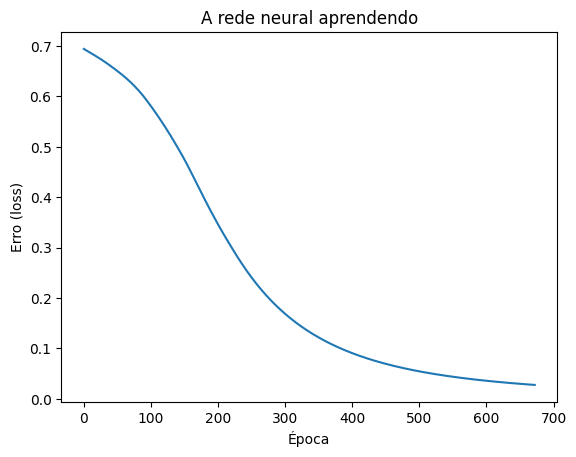

In [60]:
print("Épocas usadas no treino:", rede.n_iter_)
print("Erro na 1ª época:  ", round(rede.loss_curve_[0], 4))
print("Erro na última época:", round(rede.loss_curve_[-1], 4))

plt.plot(rede.loss_curve_)
plt.xlabel("Época")
plt.ylabel("Erro (loss)")
plt.title("A rede neural aprendendo")
plt.show()

In [61]:
vetores_novos = vectorizer.transform([lematizar(f) for f in frases_novas])
vocabulario = set(vectorizer.get_feature_names_out())

for frase, prob_lr, prob_rede in zip(frases_novas,
                                     modelo_lr.predict_proba(vetores_novos),
                                     rede.predict_proba(vetores_novos)):
    reconhecidas = [p for p in lematizar(frase).split() if p in vocabulario]
    print(frase)
    print(f"   Regressão Logística: Pos={prob_lr[1]:.2f}   |   Rede neural: Pos={prob_rede[1]:.2f}")
    print(f"   palavras que os dois modelos enxergam: {reconhecidas}")
    print()

O corretor foi excelente e muito atencioso.
   Regressão Logística: Pos=0.63   |   Rede neural: Pos=0.95
   palavras que os dois modelos enxergam: ['corretor', 'excelente']

O condomínio não foi bom, deu problema.
   Regressão Logística: Pos=0.18   |   Rede neural: Pos=0.01
   palavras que os dois modelos enxergam: ['condomínio', 'não', 'dar', 'problema']

Nossa, que ótimo, mais um atraso na entrega.
   Regressão Logística: Pos=0.55   |   Rede neural: Pos=0.64
   palavras que os dois modelos enxergam: ['entrega']

Visita agendada rapidinho, equipe nota dez.
   Regressão Logística: Pos=0.55   |   Rede neural: Pos=0.52
   palavras que os dois modelos enxergam: ['visita']



In [62]:
nome_modelo = "neuralmind/bert-base-portuguese-cased"

tokenizer = AutoTokenizer.from_pretrained(nome_modelo)
modelo_bert = AutoModel.from_pretrained(nome_modelo)

print("BERTimbau carregado.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERTimbau carregado.


In [63]:
for palavra in ["banco", "rapidinho", "atencioso", "atraso", "decepcionado"]:
    pedacos = tokenizer.tokenize(palavra)
    print(f"{palavra:14} -> {pedacos}")

print()
print("Alguma palavra virou [UNK] (desconhecida)?",
      any(tokenizer.unk_token in tokenizer.tokenize(f) for f in frases_novas))

banco          -> ['banco']
rapidinho      -> ['rap', '##idi', '##nho']
atencioso      -> ['aten', '##cioso']
atraso         -> ['atraso']
decepcionado   -> ['decep', '##cionado']

Alguma palavra virou [UNK] (desconhecida)? False


In [64]:
for palavra in ["banco", "rapidinho", "atencioso", "atraso", "decepcionado"]:
    pedacos = tokenizer.tokenize(palavra)
    print(f"{palavra:14} -> {pedacos}")

print()
print("Alguma palavra virou [UNK] (desconhecida)?",
      any(tokenizer.unk_token in tokenizer.tokenize(f) for f in frases_novas))

banco          -> ['banco']
rapidinho      -> ['rap', '##idi', '##nho']
atencioso      -> ['aten', '##cioso']
atraso         -> ['atraso']
decepcionado   -> ['decep', '##cionado']

Alguma palavra virou [UNK] (desconhecida)? False


In [65]:
def vetor_da_palavra(frase, palavra):
    entrada = tokenizer(frase, return_tensors="pt")
    with torch.no_grad():
        saida = modelo_bert(**entrada)
    tokens = tokenizer.convert_ids_to_tokens(entrada["input_ids"][0])
    posicao = tokens.index(palavra)
    return saida.last_hidden_state[0, posicao]

banco_financeiro_1 = vetor_da_palavra("O banco aprovou o empréstimo ontem.", "banco")
banco_financeiro_2 = vetor_da_palavra("O banco liberou o financiamento do apartamento.", "banco")
banco_praca = vetor_da_palavra("Sentei no banco da praça para descansar.", "banco")

def similaridade(v1, v2):
    return torch.nn.functional.cosine_similarity(v1, v2, dim=0).item()

print("Tamanho de cada vetor:", banco_financeiro_1.shape[0], "números")
print(f"banco (empréstimo) x banco (financiamento): {similaridade(banco_financeiro_1, banco_financeiro_2):.3f}")
print(f"banco (empréstimo) x banco (praça):         {similaridade(banco_financeiro_1, banco_praca):.3f}")

Tamanho de cada vetor: 768 números
banco (empréstimo) x banco (financiamento): 0.919
banco (empréstimo) x banco (praça):         0.546


In [66]:
completar = pipeline("fill-mask", model=nome_modelo)
lacuna = completar.tokenizer.mask_token          # a "lacuna" que o modelo entende: [MASK]

frase = f"O {lacuna} aprovou o financiamento da casa ontem."
print(frase)
for palpite in completar(frase, top_k=5):
    print(f"   {palpite['token_str']:15} {palpite['score']:.2f}")

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


O [MASK] aprovou o financiamento da casa ontem.
   Senado          0.26
   governo         0.18
   governador      0.05
   conselho        0.04
   Congresso       0.04


In [67]:
for palpite in completar(frase, targets=["banco", "Senado"]):    print(f"   {palpite['token_str']:15} {palpite['score']:.4f}")

   Senado          0.2556
   banco           0.0077


In [68]:
for palpite in completar(frase, top_k=20):    print(f"   {palpite['token_str']:15} {palpite['score']:.2f}")

   Senado          0.26
   governo         0.18
   governador      0.05
   conselho        0.04
   Congresso       0.04
   prefeito        0.03
   ministro        0.02
   partido         0.02
   Planalto        0.02
   Supremo         0.02
   Conselho        0.02
   senador         0.02
   PMDB            0.01
   PT              0.01
   deputado        0.01
   grupo           0.01
   presidente      0.01
   PSDB            0.01
   tribunal        0.01
   banco           0.01


In [69]:
classificador = pipeline("text-classification", model="cardiffnlp/twitter-xlm-roberta-base-sentiment")

for frase in frases_novas:
    resultado = classificador(frase)[0]
    print(f"{resultado['label']:10} ({resultado['score']:.2f}) | {frase}")

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

positive   (0.85) | O corretor foi excelente e muito atencioso.
negative   (0.89) | O condomínio não foi bom, deu problema.
negative   (0.59) | Nossa, que ótimo, mais um atraso na entrega.
positive   (0.90) | Visita agendada rapidinho, equipe nota dez.
